# Activity: Can We Trust the AI Analyst? — FreshKart Case

**Unit 4 · AI-Assisted Visualization · LLMs for EDA & Human-in-the-Loop Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

**FreshKart** is a quick-commerce grocery chain with **10 dark stores in 3 cities** (Bengaluru, Pune, Hyderabad). Operations head **Meera** has a leadership meeting tomorrow. She asked an AI analytics assistant:

> *"Summarise our business from January to September and tell me what went wrong in September."*

The assistant has produced the report below. **You are the analyst.** Meera will present whatever you sign off, so your job is to **verify, correct or reject** each AI insight using the data, and to say *why*.

**Ground rules (from the lecture):** every number must come from code you can inspect · an alert tells you where to look, a chart tells you what is true · the AI proposes, the human decides.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_orders.csv` (synthetic)

| Column | Meaning |
|---|---|
| `order_id` | unique order reference |
| `order_date` | date of order |
| `city`, `store_id` | where the order was fulfilled |
| `zone` | `Urban` or `Suburban` delivery address |
| `delivery_partner` | `Partner A` or `Partner B` |
| `items`, `discount_pct`, `order_value` | basket size, discount applied, bill value (₹) |
| `distance_km`, `delivery_minutes`, `on_time` | delivery distance, time taken, 1 if ≤ 30 min |
| `rating` | customer rating 1–5 (blank if not given) |
| `app_sessions_7d`, `loyalty_points` | customer app activity and loyalty balance |

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_orders.csv", parse_dates=["order_date"])
df.head()

,order_id,order_date,city,store_id,zone,delivery_partner,items,discount_pct,order_value,distance_km,delivery_minutes,on_time,rating,app_sessions_7d,loyalty_points
0,FK100000,2026-01-01,Bengaluru,B1,Urban,Partner A,4,15,300,3.2,22,1,NaN,6,281
1,FK100001,2026-01-01,Bengaluru,B1,Urban,Partner A,3,5,187,1.8,16,1,4.0,4,299
2,FK100002,2026-01-01,Bengaluru,B1,Suburban,Partner A,2,20,244,2.7,28,1,3.0,8,387
3,FK100003,2026-01-01,Bengaluru,B1,Urban,Partner B,7,20,1223,1.4,20,1,4.0,8,234
4,FK100004,2026-01-01,Bengaluru,B1,Urban,Partner B,6,5,1156,3.5,28,1,5.0,11,226


## The AI assistant's report (to be validated)

| # | Insight type | AI statement |
|---|---|---|
| 1 | Trend | "Bengaluru orders grew steadily from January to September, by about **+56 orders per month**." |
| 2 | Distribution | "The **average order value is ₹465**." |
| 3 | Comparison | "Pune orders **more than doubled** from Q2 to Q3 (**+117%**), so the Pune expansion is a huge success." |
| 4 | Comparison | "Hyderabad orders **fell 28%** in September compared with August, **because delivery service there got worse**." |
| 5 | Comparison | "**Partner B is more punctual than Partner A** (93% vs 87% on time), so we should route all orders to Partner B." |
| 6 | Correlation | "Longer delivery times go with lower ratings (**r = −0.32** among rated orders)." |
| 7 | Correlation | "Bigger discounts and bigger baskets move together (**r = 0.38**)." |
| 8 | Comparison | "Suburban orders take about **5 minutes longer** to deliver than urban orders." |
| 9 | Prediction | "**Orders will recover in October.**" |

---
## Part 1 · Is the data trustworthy? Profile before you believe

An AI narrates a profile, so a flawed profile gives a confident but flawed story. Compute the basics yourself.

In [2]:
profile = {
    "rows": len(df),
    "columns": df.shape[1],
    "duplicate_rows": int(df.duplicated().sum()),   # number of fully duplicated rows
    "rating_missing_pct": float(round(df["rating"].isna().mean() * 100, 1)),   # % of ratings missing
    "order_id_unique_pct": round(df["order_id"].nunique() / len(df) * 100, 1),
}
profile

{'rows': 13987, 'columns': 15, 'duplicate_rows': 70, 'rating_missing_pct': 27.6, 'order_id_unique_pct': 99.5}

mean = ₹465 | median = ₹358 | skew = 13.2


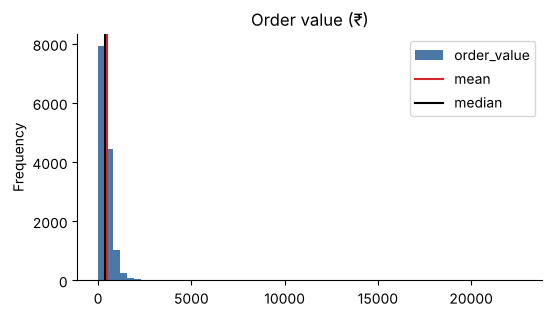

In [3]:
# From here on we work with the cleaned table (duplicates removed).
df = df.drop_duplicates().copy()

aov_mean = df["order_value"].mean()
aov_median = df["order_value"].median()
aov_skew = round(stats.skew(df["order_value"]), 1)

if ready(aov_mean, aov_median):
    print(f"mean = ₹{aov_mean:.0f} | median = ₹{aov_median:.0f} | skew = {aov_skew}")
    df["order_value"].plot.hist(bins=60, color="#4c78a8", title="Order value (₹)")
    plt.axvline(aov_mean, color="#d62728", label="mean"); plt.axvline(aov_median, color="black", label="median")
    plt.legend(); plt.show()

In [4]:
# Where are the ratings missing?
df.groupby("city")["rating"].apply(lambda s: s.isna().mean() * 100).round(1)

,rating
city,
Bengaluru,21.1
Hyderabad,45.0
Pune,20.6


**✏️ Your answer (Part 1):**
(a) Which AI insight(s) are affected by what you just found about the *average*, and how should the statement be rewritten?
(b) Insight 6 uses ratings. What risk does the missing-rating pattern create?

*Your answer:*

**(a)** Insight 2 ("the average order value is ₹465") is affected. Order value is heavily right-skewed (skew = 13.2): a few very large baskets drag the mean up to ₹465, while the median is ₹358, so the "average" overstates a typical order by about ₹107 (~30%). Rewrite: *"A typical order is worth about ₹358 (median); a small number of very large baskets lift the mean to ₹465."* (The 70 fully duplicated rows were removed first, leaving 13,917 orders.)

**(b)** 27.6% of ratings are missing, and unevenly: about 45% in Hyderabad versus about 21% in Bengaluru and Pune (and slightly more on very slow deliveries, ~35% for >40 min vs ~27% for ≤20 min). Ratings are therefore not missing at random, so r = −0.32 only describes customers who chose to rate and under-represents Hyderabad; the true relationship in all customers could be weaker or stronger. The AI should have reported the sample size, the missing share and where it is missing.

---
## Part 2 · Defaults shape the story: bin width

The assistant looked at a 1-minute-bin histogram of one store's deliveries and wrote: *"Delivery times are **multimodal**, with three separate peaks."* Look at the same 150 orders with different bin widths.

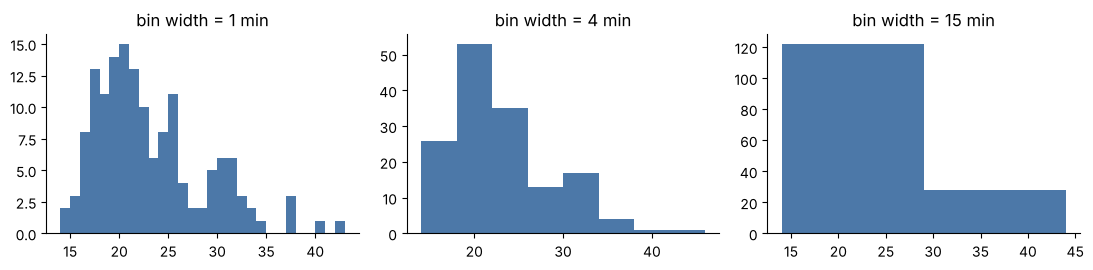

multimodal supported: False | best bin width: 4 min


In [5]:
sample = df[df.store_id == "B3"].sample(150, random_state=1)["delivery_minutes"]
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8))
for ax, w in zip(axes, [1, 4, 15]):
    ax.hist(sample, bins=np.arange(sample.min(), sample.max() + w, w), color="#4c78a8")
    ax.set_title(f"bin width = {w} min")
plt.tight_layout(); plt.show()

multimodal_supported = False    # peaks vanish at 4 min: it is sampling noise from 150 orders
best_bin_width = 4            # 1 min is noise, 15 min hides the skewed shape, 4 min shows it
print(f"multimodal supported: {multimodal_supported} | best bin width: {best_bin_width} min")

**✏️ Your answer (Part 2):** In one sentence, what should the analyst do before accepting a shape claim from an automated report?

*Your answer:*

Before accepting a shape claim, re-draw the histogram with several bin widths (and check the sample size) and only believe features that survive: here the 1-minute bins show spiky noise from just 150 orders, the 4-minute bins show one right-skewed hump, and the 15-minute bins hide the shape, so "multimodal" is not supported.

---
## Part 3 · Trends, correlations and patterns

### 3a · Trend (insight 1)

slope = 56.2 orders/month | Kendall tau = 0.89, p = 0.0002


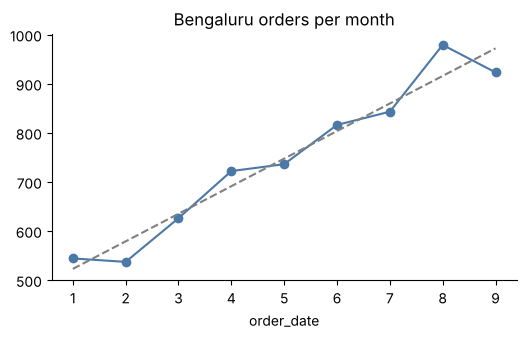

In [6]:
bengaluru = df[df.city == "Bengaluru"]
monthly = bengaluru.groupby(bengaluru["order_date"].dt.month).size()
months = monthly.index.values

slope = np.polyfit(months, monthly.values, 1)[0]   # slope of a straight-line fit of monthly orders on month
tau, p_trend = stats.kendalltau(months, monthly.values)    # Mann–Kendall-style trend test

if ready(slope):
    print(f"slope = {slope:.1f} orders/month | Kendall tau = {tau:.2f}, p = {p_trend:.4f}")
    ax = monthly.plot(marker="o", color="#4c78a8", title="Bengaluru orders per month")
    ax.plot(months, np.polyval(np.polyfit(months, monthly.values, 1), months), "--", color="grey")
    plt.show()

### 3b · Correlation (insights 6 and 7)

discount~items r = 0.38 | minutes~rating r = -0.316 | hours~rating r = -0.316


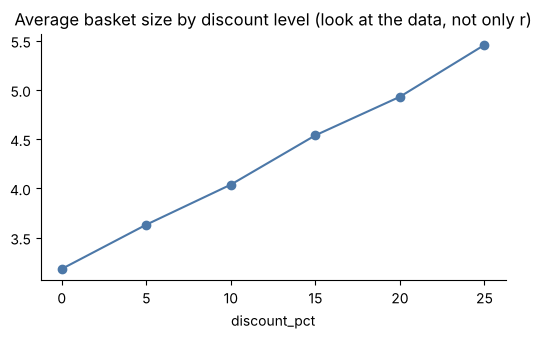

In [7]:
r_disc_items = df["discount_pct"].corr(df["items"])   # Pearson r

# Same question, different units: minutes -> hours
rated = df.dropna(subset=["rating"]).copy()
rated["delivery_hours"] = rated["delivery_minutes"] / 60
r_minutes = rated["delivery_minutes"].corr(rated["rating"])
r_hours = rated["delivery_hours"].corr(rated["rating"])
r_unchanged = bool(np.isclose(r_minutes, r_hours))   # rescaling units does not change r

if ready(r_disc_items, r_unchanged):
    print(f"discount~items r = {r_disc_items:.2f} | minutes~rating r = {r_minutes:.3f} | hours~rating r = {r_hours:.3f}")
    df.groupby("discount_pct")["items"].mean().plot(marker="o", color="#4c78a8",
        title="Average basket size by discount level (look at the data, not only r)")
    plt.show()

### 3c · Scanning many pairs

The assistant also scanned **every pair** of the 7 numeric columns below and flags any pair with p < 0.05 as a "finding".

In [8]:
num_cols = ["order_value", "items", "discount_pct", "distance_km", "delivery_minutes", "app_sessions_7d", "loyalty_points"]

n_pairs = len(list(itertools.combinations(num_cols, 2)))   # 7 choose 2
expected_false = n_pairs * 0.05   # expected false positives at alpha = 0.05
bonferroni = 0.05 / n_pairs   # Bonferroni-corrected threshold

rows = []
for a, b in itertools.combinations(num_cols, 2):
    r, p = stats.pearsonr(df[a], df[b])
    rows.append((a, b, round(r, 3), p))
scan = pd.DataFrame(rows, columns=["x", "y", "r", "p"]).sort_values("p")

if ready(n_pairs, expected_false, bonferroni):
    print(f"pairs = {n_pairs} | expected false positives = {expected_false:.2f} | Bonferroni threshold = {bonferroni:.4f}")
    flagged = scan[scan["p"] < 0.05].copy()
    flagged["survives_bonferroni"] = flagged["p"] < bonferroni
    display(flagged)

pairs = 21 | expected false positives = 1.05 | Bonferroni threshold = 0.0024


,x,y,r,p,survives_bonferroni
0,order_value,items,0.325,0.000000e+00,True
6,items,discount_pct,0.378,0.000000e+00,True
15,distance_km,delivery_minutes,0.748,0.000000e+00,True
1,order_value,discount_pct,0.066,5.802888e-15,True
14,discount_pct,loyalty_points,-0.022,8.317915e-03,False


**✏️ Your answer (3a–3c):**
(a) Insight 1 rests on 9 monthly points. Is the trend claim reasonable, and what would you show with it?
(b) Insight 7 says discounts and baskets "move together". Does the chart support the wording, and can the AI say discounts *cause* bigger baskets?
(c) Look at the flagged table. Which pair is most likely a false alarm, and what are **two** reasons you say so?

*Your answer:*

**(a)** Reasonable. The straight-line fit gives +56.2 orders/month and Kendall's τ = 0.89 (p = 0.0002), with monthly orders going from 544 in January to 923 in September, so the upward trend is real and the AI's number is right. With only 9 points I would show the monthly points themselves with the fitted line and the τ/p value rather than the slope alone, and I would soften "steadily" because September (923) is below August (979).

**(b)** Yes, the chart supports "move together": average basket size rises almost in a straight line with each discount step, from about 3.2 items at 0% to 5.5 at 25%, which matches r = 0.38 (r² ≈ 14%, a moderate link). The AI cannot say discounts *cause* bigger baskets, because this is observational data: bigger carts may unlock higher discounts (reverse direction), or promotions and customer type may drive both (confounding).

**(c)** The most likely false alarm is **discount_pct ~ loyalty_points** (r = −0.022, p = 0.008). Two reasons: (1) with 21 pairs tested we expect about 1 false positive at α = 0.05, and p = 0.008 fails the Bonferroni threshold of 0.0024 (the only flagged pair that does); (2) the effect is negligible (r² ≈ 0.05%) and there is no plausible mechanism, since with about 14,000 rows even a trivial correlation becomes "significant".

### 3d · Patterns: grouping the stores

The assistant ran **PCA + k-means (k = 3)** on store-level features and proposed three store "segments".

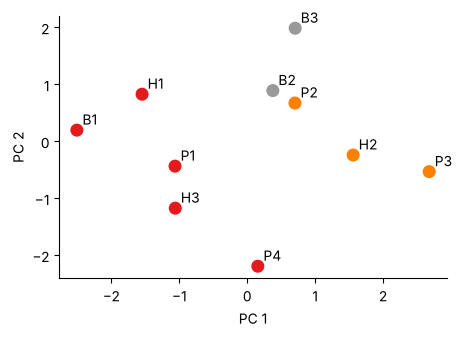

,segment,orders_per_active_day,on_time,suburban_share
store_id,,,,
B1,0,8.29,0.92,0.35
H1,0,4.99,0.91,0.35
P1,0,4.76,0.90,0.37
H3,0,4.30,0.91,0.39
P4,0,4.34,0.88,0.41
H2,1,5.24,0.89,0.45
P3,1,5.25,0.88,0.48
P2,1,4.39,0.91,0.42
B2,2,8.90,0.90,0.45


In [9]:
d = df.assign(month=df["order_date"].dt.month)
store = df.groupby("store_id").agg(
    orders=("order_id", "count"),
    median_value=("order_value", "median"),
    on_time=("on_time", "mean"),
    suburban_share=("zone", lambda s: (s == "Suburban").mean()),
    avg_discount=("discount_pct", "mean"),
    active_days=("order_date", "nunique"),
)
store["orders_per_active_day"] = store["orders"] / store["active_days"]
feats = store.drop(columns=["orders", "active_days"])

Z = StandardScaler().fit_transform(feats)
pcs = PCA(n_components=2).fit_transform(Z)
store["segment"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.scatter(pcs[:, 0], pcs[:, 1], c=store["segment"], cmap="Set1", s=70)
for sid, (x, y) in zip(store.index, pcs):
    ax.annotate(sid, (x, y), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); plt.show()
store[["segment", "orders_per_active_day", "on_time", "suburban_share"]].round(2).sort_values("segment")

In [10]:
# Extra check (added): are the three store "segments" stable enough to name?
from sklearn.metrics import silhouette_score, adjusted_rand_score
base = store["segment"].values
print(f"silhouette k=3: {silhouette_score(Z, base):.2f}   (1 = tight & separated; below ~0.25 = weak structure)")
for k in (2, 4):
    print(f"silhouette k={k}: {silhouette_score(Z, KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Z)):.2f}")
# leave-one-store-out: drop each store, re-cluster, compare with the original grouping
aris = []
for i in range(len(Z)):
    keep = np.arange(len(Z)) != i
    lab = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z[keep])
    aris.append(adjusted_rand_score(base[keep], lab))
print(f"leave-one-store-out agreement (ARI, 1 = identical): mean {np.mean(aris):.2f}, min {min(aris):.2f}")
store[["active_days", "orders_per_active_day", "on_time", "median_value"]].round(2).sort_values("active_days")

silhouette k=3: 0.21   (1 = tight & separated; below ~0.25 = weak structure)
silhouette k=2: 0.24
silhouette k=4: 0.17
leave-one-store-out agreement (ARI, 1 = identical): mean 0.71, min -0.11


,active_days,orders_per_active_day,on_time,median_value
store_id,,,,
P4,92,4.34,0.88,346.0
P3,92,5.25,0.88,373.0
H2,250,5.24,0.89,363.0
H1,271,4.99,0.91,355.0
P1,271,4.76,0.90,350.0
P2,271,4.39,0.91,369.0
B1,272,8.29,0.92,349.0
B3,272,7.50,0.89,361.0
H3,272,4.30,0.91,352.0


**✏️ Your answer (3d):** The AI says these are three meaningful store "types". With only 10 stores, what is one reason a human should hesitate, and what would you check before naming the segments?

*Your answer:*

With only 10 stores each "segment" has 2–5 members, so the grouping is fragile: the silhouette is weak (0.21, and k = 2 scores higher at 0.24), and dropping a single store can scramble it (leave-one-store-out agreement averages ARI 0.71 but falls to −0.11). The groups are also driven by artefacts rather than real "types": P3 and P4 have only 92 active days and H2 has a three-week data gap, both of which distort orders_per_active_day, while on-time (0.88–0.92) and median order value (₹346–373) barely differ between stores. Before naming them I would check stability across k, seeds and dropped stores, profile each cluster in original units after fixing the active-day artefacts, and ask operations whether the groups mean anything.

---
## Part 4 · From an observation to hypotheses (insight 4)

**Observation:** Hyderabad orders fell sharply in September. The AI jumped straight to "service got worse". A better assistant would list *competing* hypotheses and the evidence that separates them:

| | Hypothesis | Test |
|---|---|---|
| A | Delivery service got worse | on-time % in Aug vs Sep |
| B | A data problem: some store has missing rows | rows per store per week |
| C | Discounts were cut in September | mean discount, Aug vs Sep |
| D | Customers switched to a competitor | needs competitor/customer data we do not have |

In [11]:
hyd = df[df.city == "Hyderabad"]
hyd_month = hyd.groupby(hyd["order_date"].dt.month).size()

change_pct = (hyd_month[9] / hyd_month[8] - 1) * 100   # % change Aug -> Sep
first_test = 'B'     # a row-count check needs no new data and must be settled before interpreting any drop

if ready(change_pct, first_test):
    print(f"Hyderabad Aug -> Sep: {change_pct:.1f}% | cheapest test first: {first_test}")

Hyderabad Aug -> Sep: -28.4% | cheapest test first: B


In [12]:
# Run the tests for hypotheses B and A
weekly = hyd.groupby([pd.Grouper(key="order_date", freq="W"), "store_id"]).size().unstack(fill_value=0)
display(weekly.tail(9))

ontime = hyd.groupby(hyd["order_date"].dt.month)["on_time"].mean() * 100
ontime_change_pts = ontime[9] - ontime[8]   # on-time % in September minus August
culprit_store = weekly.iloc[:-1].min().idxmin()   # store with the emptiest week (last row is a partial week)

if ready(ontime_change_pts, culprit_store):
    print(f"on-time change Aug->Sep = {ontime_change_pts:+.1f} points | store with the gap: {culprit_store}")
    h2_dates = df[df.store_id == culprit_store]["order_date"].sort_values()
    gap_idx = h2_dates.diff().dt.days.idxmax()
    print(f"{culprit_store} recorded no orders between {h2_dates.shift().loc[gap_idx].date()} and {h2_dates.loc[gap_idx].date()}")
    print(f"mean discount Aug -> Sep: {hyd[hyd.order_date.dt.month == 8].discount_pct.mean():.1f}% -> {hyd[hyd.order_date.dt.month == 9].discount_pct.mean():.1f}%")

store_id,H1,H2,H3
order_date,,,
2026-08-09,33,36,39
2026-08-16,41,32,17
2026-08-23,39,35,36
2026-08-30,46,39,28
2026-09-06,37,28,36
2026-09-13,33,0,21
2026-09-20,43,0,38
2026-09-27,38,11,31
2026-10-04,17,18,19


on-time change Aug->Sep = -0.3 points | store with the gap: H2
H2 recorded no orders between 2026-09-04 and 2026-09-26
mean discount Aug -> Sep: 9.3% -> 9.5%


**✏️ Your answer (Part 4):** In two sentences, which hypotheses did the data support or rule out? Write the corrected version of insight 4 that you would be willing to show Meera.

*Your answer:*

The data **rules out A** (Hyderabad on-time rate was flat: 89.0% in August vs 88.7% in September, −0.3 points) and **C** (mean discount 9.3% → 9.5%); it **supports B**, because store H2 recorded no orders between 4 and 26 September (zero rows in two full weeks) while H1 and H3 kept reporting. D cannot be tested with this data.

**Corrected insight 4 for Meera:** *"Hyderabad's recorded orders fell 28% from August to September (483 → 346), but store H2 has no data for about 5–25 September, so most of this drop is a data gap rather than a proven fall in demand. On-time rate (−0.3 points) and discounts were unchanged, so there is no evidence that delivery service got worse; we need H2's missing orders before drawing any conclusion about demand."*

---
## Part 5 · Validate and correct two more claims

### 5a · "Pune orders more than doubled" (insight 3)

In [13]:
pune = df[df.city == "Pune"].copy()
pune["quarter"] = pune["order_date"].dt.quarter
by_store = pune.pivot_table(index="store_id", columns="quarter", values="order_id", aggfunc="count", fill_value=0)
display(by_store)

old = by_store.loc[["P1", "P2"]]                  # the stores that were open in both Q2 and Q3
like_for_like_pct = (old[3].sum() / old[2].sum() - 1) * 100   # Q3 vs Q2, P1 + P2 only

if ready(like_for_like_pct):
    print(f"like-for-like growth = {like_for_like_pct:+.1f}%")

quarter,1,2,3
store_id,,,
P1,423,423,443
P2,388,380,421
P3,0,0,483
P4,0,0,399


like-for-like growth = +7.6%


Now draw the *corrected* message. The chart below already greys the context and highlights the new stores (Knaflic: grey the context, one accent colour, title with the takeaway). **Write the title.**

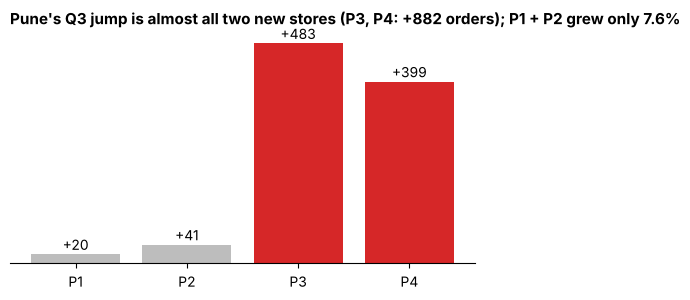

In [14]:
title = "Pune's Q3 jump is almost all two new stores (P3, P4: +882 orders); P1 + P2 grew only 7.6%"

change = by_store[3] - by_store[2]
colors = ["#bdbdbd" if s in ("P1", "P2") else "#d62728" for s in by_store.index]
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(change.index, change.values, color=colors)
for x, v in zip(change.index, change.values):
    ax.text(x, v + 10, f"{v:+d}", ha="center")
ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_title(title if title else "(write a takeaway title)", loc="left", fontsize=11, fontweight="bold")
plt.show()

### 5b · "Partner B is more punctual, send everything to B" (insight 5)

In [15]:
overall = df.groupby("delivery_partner")["on_time"].mean().mul(100).round(1)
mix = (pd.crosstab(df["delivery_partner"], df["zone"], normalize="index") * 100).round(0)
print("Overall on-time %:\n", overall, "\n\nShare of each partner's orders by zone (%):\n", mix)

by_zone = df.groupby(["zone", "delivery_partner"])["on_time"].mean().mul(100).round(1).unstack()   # on-time % per zone x partner
better_in_every_zone = 'Partner A'   # A wins in Urban and in Suburban
phenomenon = "Simpson's paradox"   # the overall ranking reverses inside every subgroup

if ready(by_zone, better_in_every_zone, phenomenon):
    display(by_zone)
    print(f"Better inside every zone: {better_in_every_zone} | effect: {phenomenon}")

Overall on-time %:
 delivery_partner
Partner A    87.1
Partner B    93.0
Name: on_time, dtype: float64 

Share of each partner's orders by zone (%):
 zone              Suburban  Urban
delivery_partner                 
Partner A             67.0   33.0
Partner B             16.0   84.0


delivery_partner,Partner A,Partner B
zone,,
Suburban,81.4,72.0
Urban,98.8,96.9


**✏️ Your answer (Part 5):** (a) Rewrite insight 3 so it is honest. (b) Explain in plain language why Partner B *looks* better overall, and what question a careful human asks before accepting a comparison like insight 5.

*Your answer:*

**(a)** Rewrite of insight 3: *"Pune orders rose 117% from Q2 to Q3 (803 → 1,746), but almost all of the increase comes from the two new stores P3 and P4 (882 orders in Q3); the two stores open in both quarters (P1 + P2) grew only 7.6% (803 → 864). The new stores are adding volume, but 'huge success' is not shown by this data; we would need their profitability and whether they pull orders from P1/P2."*

**(b)** Partner B *looks* better overall (93.0% vs 87.1%) only because of the mix of orders: 84% of B's orders are short-distance Urban deliveries, which are easy, while 67% of A's are Suburban, which are harder. Inside each zone Partner A is actually better (Urban 98.8% vs 96.9%; Suburban 81.4% vs 72.0%), which is Simpson's paradox, so routing everything to B would likely lower punctuality. A careful analyst asks: "Are the two groups doing comparable work, or does something else that affects the outcome (zone, distance) differ between them?" and compares like with like before accepting the comparison.

---
## Part 6 · Triage the whole report

For each AI insight decide: **Accept** (correct as stated), **Correct** (the finding is useful but the wording or number must change) or **Reject** (not supported). Then measure the AI.

In [16]:
decisions = {
    1: "Accept",   # Bengaluru trend
    2: "Correct",   # average order value
    3: "Correct",   # Pune doubled
    4: "Correct",   # Hyderabad fell because service worsened
    5: "Reject",   # Partner B more punctual
    6: "Accept",   # delivery time vs rating
    7: "Accept",   # discount vs basket
    8: "Accept",   # suburban slower (check it yourself: df.groupby("zone")["delivery_minutes"].mean())
    9: "Reject",   # recovery prediction
}
analysts_true_insights = 7    # true insights an expert team found in this data (given)

accepted = sum(v == "Accept" for v in decisions.values())   # insights accepted as stated
if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    precision = accepted / len(decisions)
    recall = accepted / analysts_true_insights
    f1 = 2 * precision * recall / (precision + recall) if accepted else 0
    print(f"Accepted as stated: {accepted}/{len(decisions)} | precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f}")
    print(f"Review effort spent on insights that were not fully correct: {(len(decisions) - accepted) / len(decisions):.0%}")
else:
    print("⚠ Fill in all nine decisions with 'Accept', 'Correct' or 'Reject'.")

Accepted as stated: 4/9 | precision = 0.44 | recall = 0.57 | F1 = 0.50
Review effort spent on insights that were not fully correct: 56%


**✏️ Your answer (Part 6):** Using precision and recall, would you describe this AI as an *assistant* or a *replacement* for the analyst? Justify in two sentences.

*Your answer:*

This AI behaves as an **assistant, not a replacement**: only 4 of 9 insights were correct as stated (precision 0.44, recall 0.57 against the 7 true insights, F1 0.50), so more than half of the review effort (56%) went on insights that needed correcting or rejecting. Several of the failures (insight 4's invented cause and insight 5's "send everything to B") would have driven wrong decisions if signed off unchecked, though the AI did surface useful leads that a human could then verify.

---
## Part 7 · Communicating, steering and validating

### 7a · Three kinds of reading
Each insight reads the data at a different level: **`data`** (restates what is plotted), **`between`** (relationships or patterns) or **`beyond`** (predictions and causal explanations; the risk zone).

In [17]:
levels = {
    2: 'data',   # "The average order value is ₹465."
    6: 'between',   # "Longer delivery times go with lower ratings."
    9: 'beyond',   # "Orders will recover in October."
}      # 'data', 'between' or 'beyond'
print(levels)

{2: 'data', 6: 'between', 9: 'beyond'}


### 7b · Steering the assistant (interactive refinement)
Match each thing Meera types to the kind of feedback it is: **Reject**, **Constrain**, **Steer**, **Adjust** or **Pin**.

In [18]:
user_actions = {
    '"Never use pie charts in this report"': 'Constrain',
    '"Use 5-minute bins for delivery time"': 'Adjust',
    '"Focus on on-time rate by city"': 'Steer',
    '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',
    '"Not this chart again"': 'Reject',
}   # one of 'Reject', 'Constrain', 'Steer', 'Adjust', 'Pin'
user_actions

{'"Never use pie charts in this report"': 'Constrain', '"Use 5-minute bins for delivery time"': 'Adjust', '"Focus on on-time rate by city"': 'Steer', '"Keep the like-for-like Pune chart on the dashboard"': 'Pin', '"Not this chart again"': 'Reject'}

### 7c · Which validation threat?
Meera now says: *"My real worry is why **repeat customers** are leaving. The AI answered a different question: how orders changed."* The AI's numbers were all computed correctly.

In [19]:
threat = 'wrong problem'   # Munzner: the numbers are right but the question is not the user's question
threat

'wrong problem'

**✏️ Your answer (Part 7):** Rewrite insight 2 *and* insight 4 as statements you would be comfortable presenting. Each rewrite should use the right measure or the right scope, avoid causal language the data cannot support, and be specific (no "interesting variation").

*Your answer:*

**Insight 2 (rewritten, right measure):** *"A typical FreshKart order is worth about ₹358 (the median, across 13,917 orders from January to September). The average of ₹465 is higher because a small number of very large baskets pull it up, so we use the median to describe a typical customer."*

**Insight 4 (rewritten, right scope, no causal claim):** *"Recorded Hyderabad orders fell 28% from August to September (483 → 346). Store H2 has no recorded orders from about 5 to 25 September, so this figure mixes a data gap with any real change in demand. Delivery performance (on-time 89.0% → 88.7%) and discounts (9.3% → 9.5%) were stable, so we have no evidence that service worsened; H2's missing data needs to be recovered before we judge demand."*

---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which AI insight did you find most convincing? What made it convincing (the number, the tone, the chart, the confident wording), and would you have caught the problem without the checks?

*Your reflection:*

Before checking anything I found insight 5 (Partner B is 93% vs 87% punctual, so route everything to B) the most convincing: it had precise numbers, a clear recommendation and a confident tone, and the 6-point gap looked large. I would not have caught the problem without the split by zone, because the overall comparison is correct arithmetic; the flaw is only visible when you compare like with like.

**2. Choosing the level of automation.** For FreshKart, name one task where you would let the AI work with little supervision and one where you would insist on a human check. What did you use to decide (stakes, reversibility, how visible errors are)?

*Your reflection:*

I would let the AI work with little supervision on routine, reversible, easily-checked tasks such as profiling the data (row counts, duplicates, % missing) and drawing standard monthly charts, since errors there are cheap and obvious. I would insist on a human check for anything that explains *why* something happened or triggers an action (insight 4's cause, insight 5's routing change), because the stakes are higher, the action is hard to reverse and the errors are invisible in the output.

**3. Making trust cheaper.** Pick one problem you found (e.g. the Hyderabad gap, the missing ratings, or Partner B). What should the AI tool have *shown* (code, sample size, data gaps, uncertainty) so you could verify it faster, and what control would you want (edit, undo, switch off)?

*Your reflection:*

The Hyderabad gap is the one I would fix first. The tool should have shown the code and a data-coverage view (rows per store per week) with an explicit warning that H2 had no data for three weeks, plus the sample sizes behind each number, so I could verify it in seconds rather than discover it by searching. As controls I would want to exclude or edit a store, undo a change, and switch off causal wording ("because...") unless a test supports it.

**4. Responsibility.** If Meera presents the corrected report and one number is still wrong, who is accountable, the AI, the tool's vendor, you or Meera? What would you do differently next time to carry that responsibility well?

*Your reflection:*

Meera is accountable for what she presents, and as the analyst who signed off I share that responsibility; the AI and its vendor can be blamed for a tool failure, but they cannot be held responsible for a decision. Next time I would keep a short validation log of what I checked and how, label each number with its sample size and caveats, and mark anything I could not verify as unverified so Meera presents it with the right level of confidence.